<a href="https://colab.research.google.com/github/Evelandya/aprendizaje-automatico-1/blob/main/AA1_TP3_Taller_redes_neuronales_sklearn_clasificaci%C3%B3n_Evelyn_Tramontin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller: Redes neuronales con scikit-learn
### Clasificación desde un enfoque de "caja negra"

**Curso:** Minería de Datos

---

## ¿Qué vamos a aprender?

Al terminar este taller vas a poder:

1. Entrenar una **red neuronal** (perceptrón multicapa) para **clasificación** con `scikit-learn`.
2. Preparar los datos correctamente para que la red funcione (¡esto es más importante de lo que parece!).
3. **Analizar resultados**: métricas, gráficos, errores, variabilidad y qué variables importan.
4. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` y `RandomizedSearchCV`).
5. Aplicar todo lo anterior por tu cuenta en dos problemas nuevos.

## Cómo trabajar con este notebook

- Ejecutá las celdas **en orden** (`Shift + Enter`). Muchas dependen de las anteriores.
- Los bloques con 🤔 **Para pensar** son preguntas para que discutas con tus compañeros antes de seguir.
- Al final hay **actividades** para resolver solos/as reutilizando lo que vimos.
- Este notebook está pensado para **Google Colab**: guardá tu propia copia con `Archivo → Guardar una copia en Drive`.
- No pasa nada si algo falla: ¡equivocarse es parte del proceso! Podés volver a ejecutar cualquier celda.

## 📑 Contenido

| Parte | Tema |
|---|---|
| 0 | La idea general: ¿qué es una red neuronal (MLP)? |
| 1 | Preparación del entorno |
| 2 | **Regresión**: predecir el consumo de combustible de autos |
| 3 | **Clasificación**: identificar especies de pingüinos |
| 4 | Resumen y buenas prácticas |
| 5 | **Actividades** para resolver por tu cuenta |

---
# Parte 0 · La idea general

## ¿Qué es un perceptrón multicapa (MLP)?

Un **MLP** (*Multi-Layer Perceptron*) es una red neuronal formada por capas de "neuronas" conectadas entre sí:

```
 Variables de           Capas ocultas            Salida
  entrada          (aquí "ocurre la magia")
                                                   
   x1 ──┐          ┌─ ○ ─┐      ┌─ ○ ─┐
   x2 ──┼────────► │  ○  │ ───► │  ○  │ ───────►  predicción
   x3 ──┤          │  ○  │      └─ ○ ─┘
   ...  ┘          └─ ○ ─┘
```

Cada neurona hace algo muy simple: **combina las entradas con unos pesos, suma y aplica una función de activación** (por ejemplo, ReLU). Al apilar muchas neuronas y varias capas, la red puede aprender relaciones **no lineales** complejas.

El entrenamiento consiste en **ajustar los pesos** para que las predicciones se parezcan cada vez más a los valores reales. Esto se hace de forma iterativa (descenso de gradiente): en cada *época* la red ve los datos, mide su error y corrige un poquito los pesos.

## El enfoque "caja negra"

En este taller **no vamos a programar la red ni a derivar ecuaciones**. Vamos a tratarla como una **caja negra configurable**:

- 📥 Le damos datos (bien preparados).
- 🎛️ Ajustamos unos "botones" (**hiperparámetros**).
- 📊 Evaluamos qué tan bien predice y qué variables influyen.

> Esto **no** significa usarla a ciegas: significa saber **qué botones existen, qué hacen y cómo verificar que el resultado es confiable**.

## Los "botones" principales de `MLPRegressor` / `MLPClassifier`

| Hiperparámetro | ¿Qué controla? | Valores típicos |
|---|---|---|
| `hidden_layer_sizes` | Arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. `(64, 32)` = 2 capas, de 64 y 32 neuronas | `(16,)`, `(64,)`, `(64, 32)` |
| `activation` | Función de activación de las capas ocultas | `"relu"`, `"tanh"`, `"logistic"` |
| `solver` | Algoritmo de optimización | `"adam"` (por defecto), `"lbfgs"` (bueno en datasets chicos), `"sgd"` |
| `alpha` | **Regularización** (penaliza pesos grandes → evita sobreajuste) | `0.0001` a `1` |
| `learning_rate_init` | Tamaño de los "pasos" de aprendizaje (solvers `adam`/`sgd`) | `0.0001` a `0.1` |
| `max_iter` | Máximo de épocas de entrenamiento | `500`, `1000`, `2000` |
| `early_stopping` | Corta el entrenamiento cuando deja de mejorar en validación | `True` / `False` |
| `random_state` | Semilla aleatoria (los pesos iniciales son aleatorios) | cualquier entero |

---
# Parte 1 · preparación del entorno

Importamos las librerías que vamos a usar. En Google Colab ya vienen instaladas, no hace falta instalar nada.

In [2]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo! 🎉")

¡Todo listo! 🎉


---
# Parte 3 · Clasificación con `MLPClassifier`

Ya conocemos el flujo. Ahora lo vamos a aplicar a **clasificación**, donde en vez de predecir un número, predecimos una **categoría**. Vas a ver que el código es muy parecido.

## El problema: ¿de qué especie es este pingüino?

Usaremos el dataset público **Palmer Penguins**: medidas de pingüinos de tres especies (*Adelie*, *Chinstrap* y *Gentoo*) de las islas del archipiélago Palmer, en la Antártida.

> **Variable objetivo (categórica):** `species` → problema de **clasificación multiclase** (3 clases).

In [3]:
url_pinguinos = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df_ping = pd.read_csv(url_pinguinos)

print(f"Dimensiones: {df_ping.shape}")
df_ping.head()

Dimensiones: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
# Valores faltantes y distribución de las clases
print("Valores faltantes por columna:")
print(df_ping.isna().sum())

print("\nDistribución de especies:")
print(df_ping["species"].value_counts())

Valores faltantes por columna:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Distribución de especies:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


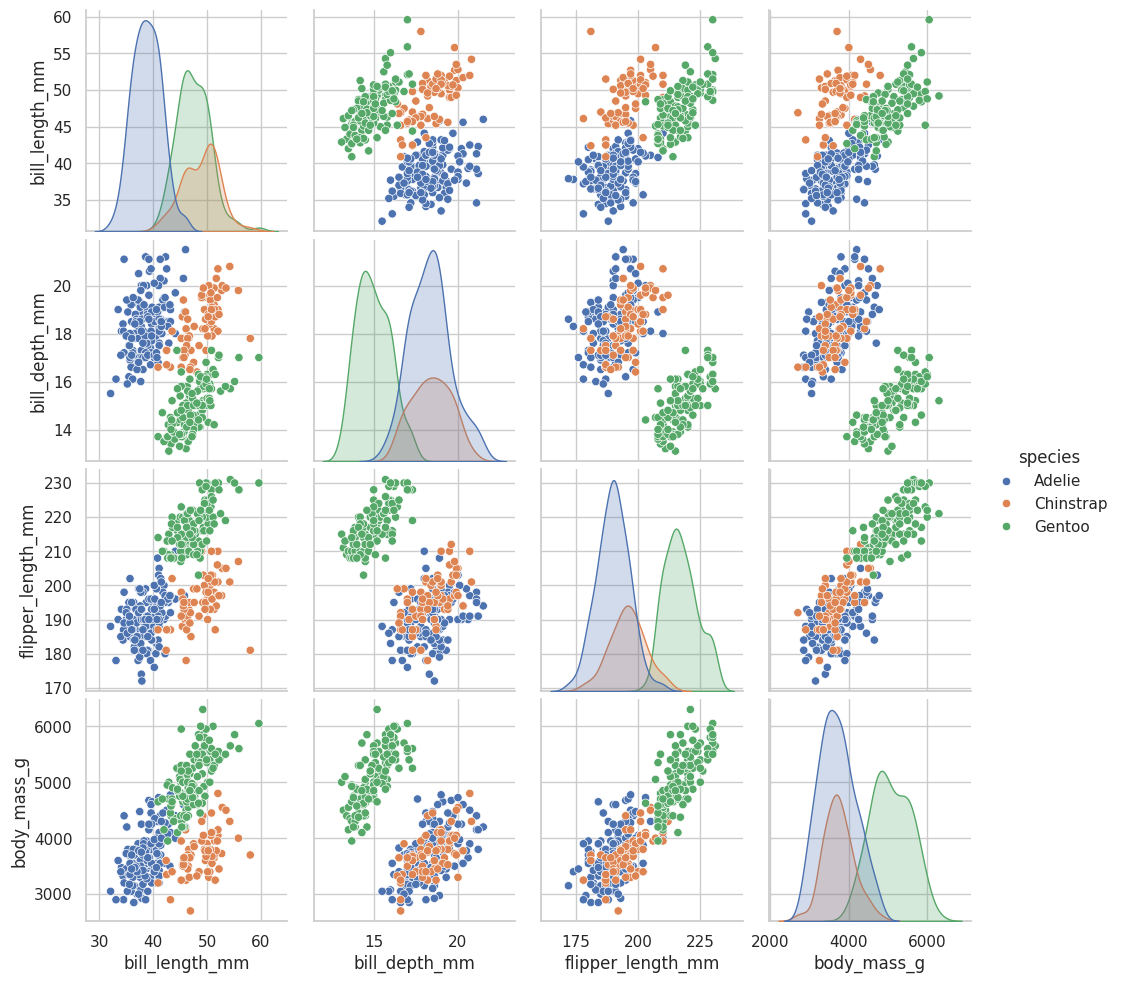

In [5]:
# Relación entre variables, coloreando por especie
sns.pairplot(df_ping, hue="species", vars=["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
plt.show()

### 🤔 Para pensar
- ¿Qué pares de variables separan mejor las tres especies?
- ¿Cuánta dificultad esperás que tenga este problema para un clasificador?

**RESPUESTAS:**

Considero que los pares que mejor permiten diferenciar las tres especies son bill_length_mm y bill_depth_mm, ya que se observa que cada especie tiende a agruparse en zonas diferentes del gráfico. Por ejemplo, los pingüinos Gentoo tienen un pico relativamente más corto y menos profundo, los Chinstrap tienen picos más largos y los Adelie presentan picos más cortos y profundos.

Espero que sea un problema de dificultad moderada, ya que las tres especies presentan agrupaciones bastante definidas según sus características físicas. Esto debería permitir que el clasificador aprenda a diferenciarlas con bastante precisión. Sin embargo, no espero una clasificación perfecta, porque hay zonas donde las especies se superponen, especialmente entre Adelie y Chinstrap. Por eso, el modelo podría tener algunas dificultades para clasificar correctamente ciertos ejemplares que presentan medidas similares.

En general, considero que es un buen problema para aplicar un clasificador, porque las variables tienen una relación clara con la especie, aunque existen algunos casos que pueden generar errores de predicción.

## Paso 1 · Preparación y división de datos

Igual que antes, pero con dos diferencias:

- Las variables categóricas (`island`, `sex`) también tienen faltantes, así que las imputamos con la **moda** (`most_frequent`).
- Al dividir usamos **`stratify=y`**: así entrenamiento y prueba mantienen **la misma proporción de cada especie**. Es muy recomendable en clasificación.

In [6]:
X_p = df_ping.drop(columns=["species"])
y_p = df_ping["species"]

X_ent_p, X_prueba_p, y_ent_p, y_prueba_p = train_test_split(
    X_p, y_p,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y_p          # mantiene las proporciones de cada clase
)

print("Proporción de clases en entrenamiento:")
print(y_ent_p.value_counts(normalize=True).round(3))

Proporción de clases en entrenamiento:
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64


In [7]:
cols_num_p = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cols_cat_p = ["island", "sex"]

preprocesador_clf = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_p),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),     # moda para categóricas
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_p)
])

## Paso 2 · Baselines y primera red neuronal

Comparamos:
- **Dummy**: siempre predice la clase más frecuente.
- **Regresión logística**: clasificador lineal simple.
- **MLP**: nuestra red neuronal.

In [8]:
# Función para evaluar clasificadores
def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_prueba": f1_score(y_prueba, pred_prueba, average="macro"),
    }

resultados_clf = []

# Baseline 1: Dummy
dummy_clf = Pipeline([("prep", preprocesador_clf), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(dummy_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Dummy (clase mayoritaria)"))

# Baseline 2: Regresión logística
logit_clf = Pipeline([("prep", preprocesador_clf), ("modelo", LogisticRegression(max_iter=1000))])
logit_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(logit_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Regresión logística"))

# Nuestra primera red neuronal para clasificar
mlp_clf = Pipeline([
    ("prep", preprocesador_clf),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])
mlp_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(mlp_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP inicial (32,16)"))

pd.DataFrame(resultados_clf)

,modelo,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
0,Dummy (clase mayoritaria),0.444,0.435,0.202
1,Regresión logística,0.993,1.000,1.000
2,"MLP inicial (32,16)",1.000,0.986,0.983


### ¿Cómo leer las métricas de clasificación?

- **Accuracy (exactitud)**: proporción de aciertos totales. Es intuitiva, pero puede engañar si las clases están desbalanceadas.
- **F1 macro**: promedia el F1 (balance entre precisión y sensibilidad) de cada clase **dándoles el mismo peso**. Es más justa cuando hay clases minoritarias.
- Compará siempre contra el **Dummy**: nos dice el "piso" que hay que superar.

### 🤔 Para pensar



¿ por qué es importante considerar otras métricas además del Accuracy?

**RESPUESTA:**

Es importante considerar otras métricas además del Accuracy porque esta medida solamente indica el porcentaje total de predicciones correctas, pero no nos muestra cómo se comporta el modelo al clasificar cada especie.

Por ejemplo, un modelo puede tener un Accuracy alto y, aun así, presentar dificultades para reconocer correctamente alguna de las especies. Por eso es importante analizar también otras métricas, como Precision, Recall y F1-score, que nos permiten evaluar con mayor detalle los aciertos, los errores y la capacidad del modelo para identificar cada clase.

En conclusión, considero que utilizar varias métricas nos permite tener una evaluación más completa y confiable del modelo, detectar posibles errores de clasificación y saber si realmente está aprendiendo a diferenciar las tres especies de pingüinos.

## Paso 3 · Analizar resultados de clasificación

### Reporte por clase y matriz de confusión

- El **reporte de clasificación** muestra precisión, sensibilidad (*recall*) y F1 **para cada clase**.
- La **matriz de confusión** muestra qué clases se confunden entre sí: filas = clase real, columnas = clase predicha. Lo ideal es que solo la diagonal tenga valores.

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



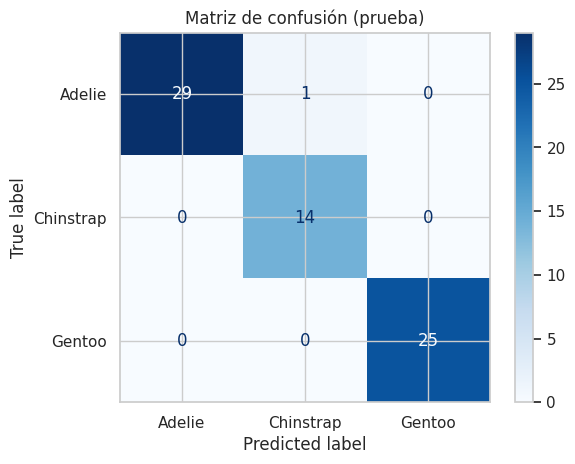

In [9]:
pred_p = mlp_clf.predict(X_prueba_p)

print(classification_report(y_prueba_p, pred_p))

ConfusionMatrixDisplay.from_estimator(mlp_clf, X_prueba_p, y_prueba_p, cmap="Blues")
plt.title("Matriz de confusión (prueba)")
plt.show()

### Probabilidades de cada clase

Un `MLPClassifier` no solo dice "esta es la clase X": también nos da **la probabilidad estimada de cada clase** con `predict_proba`. Esto es muy útil para saber **qué tan seguro** está el modelo.

In [10]:
# Probabilidades para los primeros 5 pingüinos de prueba
probabilidades = pd.DataFrame(
    mlp_clf.predict_proba(X_prueba_p.head()),
    columns=mlp_clf.classes_           # los nombres de las clases
)
probabilidades["predicha"] = mlp_clf.predict(X_prueba_p.head())
probabilidades["real"] = y_prueba_p.head().values
probabilidades.round(3)

,Adelie,Chinstrap,Gentoo,predicha,real
0,0.984,0.012,0.004,Adelie,Adelie
1,0.999,0.001,0.000,Adelie,Adelie
2,0.003,0.001,0.996,Gentoo,Gentoo
3,0.001,0.000,0.999,Gentoo,Gentoo
4,0.007,0.993,0.000,Chinstrap,Chinstrap


In [11]:
# ¿Dónde se equivoca el modelo? Miramos los casos mal clasificados
errores = X_prueba_p.copy()
errores["real"] = y_prueba_p
errores["predicha"] = pred_p
errores[errores["real"] != errores["predicha"]]

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,real,predicha
37,Dream,42.2,18.5,180.0,3550.0,FEMALE,Adelie,Chinstrap


### 🤔 Para pensar
- ¿Qué tan difícil resultó este problema? ¿Cuánto mejora la red respecto de la regresión logística?
- Si el modelo casi no se equivoca, ¿cuánto margen de mejora nos queda para el ajuste de hiperparámetros?

Considero que este problema resultó relativamente sencillo, porque las tres especies de pingüinos presentan características físicas que permiten diferenciarlas bastante bien. Esto se refleja en los resultados obtenidos por ambos modelos.

Al comparar los resultados, la regresión logística obtuvo un Accuracy de 1.00 (100%), mientras que la red neuronal obtuvo 0.986 (98,6%). Por lo tanto, en este caso la red neuronal no mejora el resultado de la regresión logística, sino que queda ligeramente por debajo.

Por otro lado, considero que queda muy poco margen de mejora, porque la red neuronal ya consigue un Accuracy del 98,6% y un F1 macro de 0.983. Esto significa que clasifica correctamente casi todos los ejemplares.

Además, la regresión logística ya alcanzó un 100% de Accuracy, por lo que difícilmente el ajuste de hiperparámetros de la red neuronal consiga una mejora significativa. En este caso, el ajuste serviría principalmente para intentar reducir el pequeño error que todavía tiene el modelo, aunque la mejora posible es limitada.

## Paso 4 · Ajuste de hiperparámetros con `RandomizedSearchCV`

Cuando hay **muchos hiperparámetros**, una grilla completa se vuelve enorme. `RandomizedSearchCV` es una alternativa: en vez de probar todas las combinaciones, **sortea `n_iter` combinaciones al azar** de las distribuciones que le indicamos. Suele encontrar buenas configuraciones con mucho menos costo.

Para parámetros continuos como `alpha` usamos `loguniform`: sortea valores en escala logarítmica (tiene sentido porque nos interesa probar 0.0001, 0.001, 0.01..., no solo valores entre 0 y 1).

Además usamos **`StratifiedKFold`** para que cada partición de la validación cruzada conserve las proporciones de clases, y optimizamos **`f1_macro`**.

In [12]:
# Distribuciones / listas de valores a explorar
distribuciones = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": loguniform(1e-5, 1e0),                # entre 0.00001 y 1
    "mlp__learning_rate_init": loguniform(1e-4, 1e-1),  # (solo afecta al solver "adam")
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busqueda_clf = RandomizedSearchCV(
    estimator=mlp_clf,
    param_distributions=distribuciones,
    n_iter=20,                  # cantidad de combinaciones aleatorias a probar
    cv=validacion,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=SEMILLA,
    verbose=1
)

busqueda_clf.fit(X_ent_p, y_ent_p)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_clf.best_params_.items():
    print(f"  {parametro}: {valor}")
print(f"\nMejor F1 macro en validación cruzada: {busqueda_clf.best_score_:.3f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits

Mejores hiperparámetros:
  mlp__activation: tanh
  mlp__alpha: 2.8381292701126715e-05
  mlp__hidden_layer_sizes: (64, 32)
  mlp__learning_rate_init: 0.0003972110727381913
  mlp__solver: adam

Mejor F1 macro en validación cruzada: 0.997


In [13]:
res_c = pd.DataFrame(busqueda_clf.cv_results_)
columnas_c = ["param_mlp__hidden_layer_sizes", "param_mlp__activation", "param_mlp__solver",
              "param_mlp__alpha", "mean_test_score", "std_test_score", "rank_test_score"]

res_c.sort_values("rank_test_score")[columnas_c].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__activation,param_mlp__solver,param_mlp__alpha,mean_test_score,std_test_score,rank_test_score
6,"(64, 32)",tanh,adam,2.838e-05,0.997,0.006,1
7,"(32,)",relu,adam,1.707e-05,0.997,0.006,1
14,"(64, 32)",tanh,adam,4.298e-01,0.997,0.006,1
15,"(32, 16)",tanh,adam,4.233e-04,0.997,0.006,1
12,"(64, 32)",tanh,lbfgs,1.336e-03,0.997,0.006,1
13,"(16,)",relu,lbfgs,7.046e-01,0.997,0.006,1
9,"(32, 16)",tanh,lbfgs,3.335e-04,0.997,0.006,1
16,"(64,)",tanh,adam,6.703e-01,0.997,0.006,1


> 💡 **Observación importante:** en este dataset, muchas configuraciones distintas logran resultados casi idénticos (¡y muy altos!). Cuando el problema es "fácil" y el modelo simple ya rinde muy bien, **ajustar hiperparámetros aporta poco**: las diferencias entre configuraciones quedan dentro del ruido (`std_test_score`). En problemas más difíciles, el ajuste suele marcar más diferencia.

In [14]:
mejor_clf = busqueda_clf.best_estimator_

resultados_clf.append(evaluar_clasificacion(mejor_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP optimizado (RandomSearch)"))
pd.DataFrame(resultados_clf).set_index("modelo")

,accuracy_entrenamiento,accuracy_prueba,F1_macro_prueba
modelo,,,
Dummy (clase mayoritaria),0.444,0.435,0.202
Regresión logística,0.993,1.000,1.000
"MLP inicial (32,16)",1.000,0.986,0.983
MLP optimizado (RandomSearch),1.000,0.986,0.983


## Paso 5 · ¿Qué variables usa el modelo para decidir?

Repetimos la **importancia por permutación**, ahora con `accuracy` como métrica.

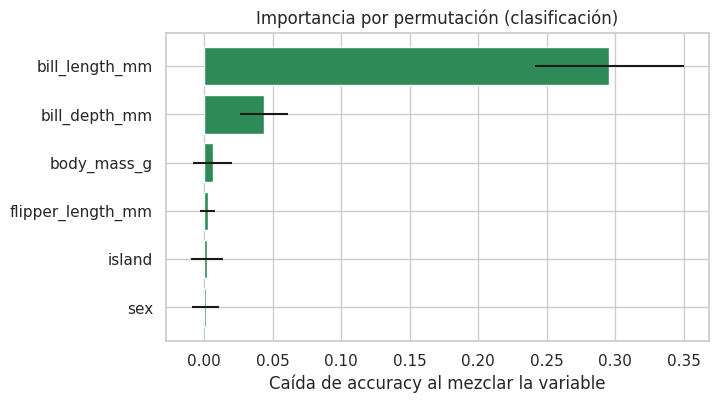

In [15]:
imp_c = permutation_importance(
    mejor_clf, X_prueba_p, y_prueba_p,
    n_repeats=30, scoring="accuracy", random_state=SEMILLA
)

importancias_c = pd.DataFrame({
    "variable": X_prueba_p.columns,
    "caida_accuracy": imp_c.importances_mean,
    "desvio": imp_c.importances_std
}).sort_values("caida_accuracy")

plt.figure(figsize=(7, 4))
plt.barh(importancias_c["variable"], importancias_c["caida_accuracy"], xerr=importancias_c["desvio"], color="seagreen")
plt.xlabel("Caída de accuracy al mezclar la variable")
plt.title("Importancia por permutación (clasificación)")
plt.show()

---
# Parte 4 · Resumen y buenas prácticas

## La receta que usamos (sirve para regresión y clasificación)

1. **Explorar** los datos (tipos, faltantes, distribuciones).
2. **Dividir** en entrenamiento y prueba (con `stratify` si es clasificación).
3. **Preprocesar dentro de un `Pipeline`**: imputar → escalar numéricas → codificar categóricas.
4. Entrenar **modelos de referencia** (Dummy, lineal/logístico) para tener con qué comparar.
5. Entrenar la **red neuronal** y **analizar resultados** (métricas, gráficos, errores).
6. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` / `RandomizedSearchCV`), usando **solo** el conjunto de entrenamiento.
7. **Evaluar una sola vez** en el conjunto de prueba.
8. **Interpretar** con importancia por permutación y **reportar** con honestidad (¡incluida la variabilidad!).

## ✅ Checklist rápido

| Situación | Qué hacer |
|---|---|
| `ConvergenceWarning` (o `n_iter_` igual a `max_iter`) | Aumentar `max_iter`, verificar que las variables estén escaladas, probar otro `solver` |
| Rendimiento muy bueno en entrenamiento y malo en prueba (sobreajuste) | Aumentar `alpha`, reducir neuronas, usar `early_stopping=True`, conseguir más datos |
| Rendimiento malo en ambos (subajuste) | Más neuronas/capas, más épocas, mejores variables |
| Resultados que cambian mucho entre corridas | Fijar `random_state`, comparar con validación cruzada, repetir con varias semillas |
| Dataset muy pequeño | Probar `solver="lbfgs"` |
| Clases desbalanceadas | No confiar solo en accuracy: mirar F1 macro, recall por clase y matriz de confusión |

## Ventajas y limitaciones de los MLP

** Ventajas:** capturan relaciones no lineales e interacciones complejas sin que las especifiquemos.

**Limitaciones:** son sensibles a la escala, tienen muchos hiperparámetros, son poco interpretables y suelen no superar a otros métodos (como bosques aleatorios o *gradient boosting*) en datos tabulares pequeños. ¡Siempre comparalos!

>  `scikit-learn` es ideal para aprender y para problemas tabulares pequeños o medianos. Para redes profundas, imágenes, texto o mucho volumen de datos se usan librerías como **PyTorch** o **TensorFlow/Keras**.

---
# Parte 5. Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

---
## Actividad 2 · Clasificación: ¿quién sobrevivió al Titanic?

**Dataset:** `titanic` (público, repositorio de datos de `seaborn`). Cada fila es un pasajero y la variable objetivo es `survived` (1 = sobrevivió, 0 = no sobrevivió).

 **Objetivo:** construir un clasificador binario con una red neuronal, analizar sus errores y ajustar hiperparámetros.

 **Te sirve de guía:** Parte 3 (Clasificación).

Este dataset es **más difícil** que el de pingüinos: tiene más faltantes y no hay una separación tan clara entre clases. ¡Aquí el ajuste y el análisis sí van a importar!

In [16]:
url_titanic = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_tit = pd.read_csv(url_titanic)

df_tit.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.250,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.283,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.925,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.100,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.050,S,Third,man,True,NaN,Southampton,no,True


**2.1 · Exploración y selección de variables.**

**Cuidado con las "trampas":** el dataset incluye columnas redundantes o que **revelan directamente la respuesta**. Por ejemplo, `alive` contiene "yes"/"no" y es equivalente a `survived`. Usarla como predictora sería un caso de **fuga de información (*data leakage*)**: el modelo tendría un rendimiento espectacular... pero completamente inútil en la vida real.

Otras columnas (`class`, `who`, `adult_male`, `embark_town`, `alone`) repiten información de columnas que ya existen, y `deck` tiene demasiados faltantes.

Trabajá **solo** con estas variables predictoras:

- Numéricas: `pclass`, `age`, `sibsp`, `parch`, `fare`
- Categóricas: `sex`, `embarked`

Explorá: ¿cuál es la proporción de sobrevivientes? ¿Cuántos faltantes tiene cada variable elegida? ¿Cómo cambia la supervivencia según `sex` y `pclass`?

In [17]:
# Variables predictoras
variables = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "sex",
    "embarked"
]

# Variable objetivo
objetivo = "survived"

# Creamos un nuevo DataFrame
df_titanic = df_tit[variables + [objetivo]].copy()

df_titanic.head()

,pclass,age,sibsp,parch,fare,sex,embarked,survived
0,3,22.0,1,0,7.250,male,S,0
1,1,38.0,1,0,71.283,female,C,1
2,3,26.0,0,0,7.925,female,S,1
3,1,35.0,1,0,53.100,female,S,1
4,3,35.0,0,0,8.050,male,S,0


In [18]:
# Cantidad de pasajeros por categoría
print(df_titanic["survived"].value_counts())

# Proporción porcentual
proporcion = df_titanic["survived"].value_counts(normalize=True) * 100

print(proporcion)

survived
0    549
1    342
Name: count, dtype: int64
survived
0    61.616
1    38.384
Name: proportion, dtype: float64


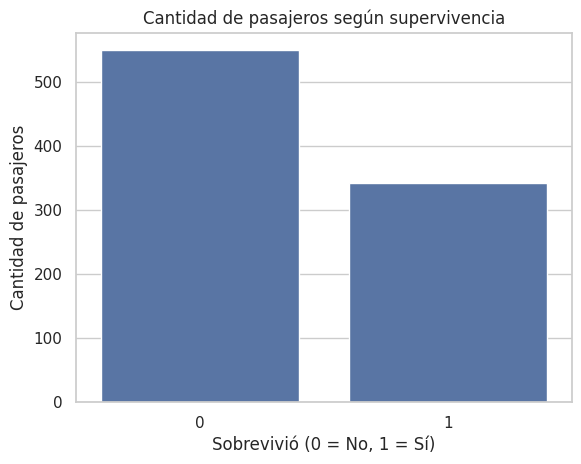

In [19]:
sns.countplot(data=df_titanic, x="survived")

plt.title("Cantidad de pasajeros según supervivencia")
plt.xlabel("Sobrevivió (0 = No, 1 = Sí)")
plt.ylabel("Cantidad de pasajeros")
plt.show()

Podemos observar que sobrevivió aproximadamente el 38,4 % de los pasajeros, mientras que el 61,6 % no sobrevivió.

Esto indica que las clases están algo desbalanceadas, porque hay más pasajeros que no sobrevivieron que pasajeros que sí lo hicieron. Por eso, más adelante no conviene evaluar el modelo solamente con Accuracy.

In [20]:
# Cantidad de valores faltantes por variable
faltantes = df_titanic.isnull().sum()

print(faltantes)

pclass        0
age         177
sibsp         0
parch         0
fare          0
sex           0
embarked      2
survived      0
dtype: int64


In [21]:
# Porcentaje de valores faltantes
porcentaje_faltantes = (
    df_titanic.isnull().mean() * 100
).round(2)

resumen_faltantes = pd.DataFrame({
    "Valores faltantes": faltantes,
    "Porcentaje (%)": porcentaje_faltantes
})

resumen_faltantes

,Valores faltantes,Porcentaje (%)
pclass,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
sex,0,0.00
embarked,2,0.22
survived,0,0.00


La variable con mayor cantidad de valores faltantes es age, con 177 registros (19,87 %). embarked tiene solamente 2 valores faltantes, mientras que las demás variables seleccionadas no presentan valores faltantes. Por lo tanto, será necesario realizar una imputación antes de entrenar el modelo.

In [22]:
# Proporción de supervivencia según sexo
supervivencia_sexo = pd.crosstab(
    df_titanic["sex"],
    df_titanic["survived"],
    normalize="index"
) * 100

print(supervivencia_sexo)

survived       0       1
sex                     
female    25.796  74.204
male      81.109  18.891


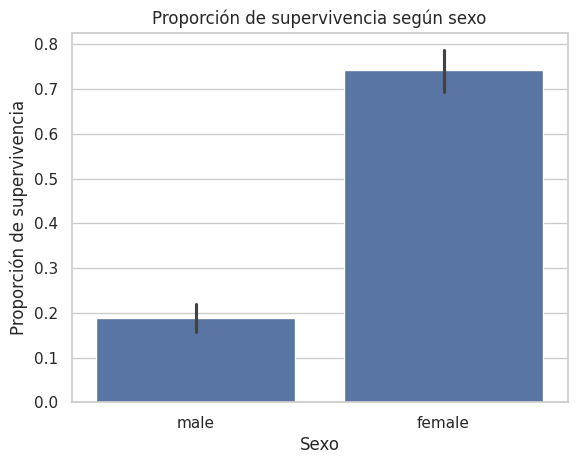

In [23]:
sns.barplot(
    data=df_titanic,
    x="sex",
    y="survived"
)

plt.title("Proporción de supervivencia según sexo")
plt.xlabel("Sexo")
plt.ylabel("Proporción de supervivencia")
plt.show()

Se observa una diferencia muy marcada en la supervivencia según el sexo. Aproximadamente el 74,2 % de las mujeres sobrevivió, mientras que entre los hombres solamente sobrevivió el 18,9 %.

Esto indica que la variable sex tiene una relación importante con la supervivencia y probablemente sea una de las variables predictoras más relevantes para el clasificador.

In [24]:
# Proporción de supervivencia según clase
supervivencia_clase = pd.crosstab(
    df_titanic["pclass"],
    df_titanic["survived"],
    normalize="index"
) * 100

print(supervivencia_clase)

survived       0       1
pclass                  
1         37.037  62.963
2         52.717  47.283
3         75.764  24.236


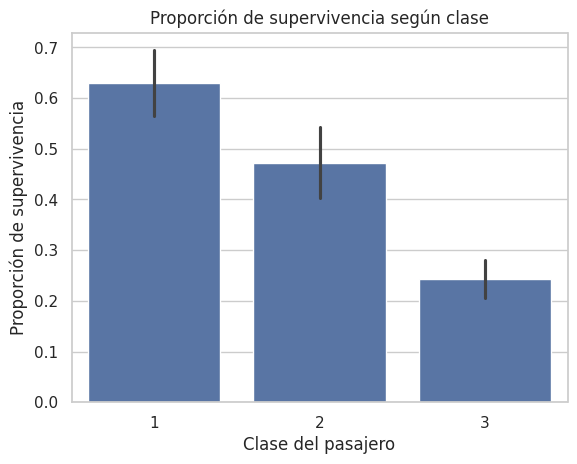

In [25]:
sns.barplot(
    data=df_titanic,
    x="pclass",
    y="survived"
)

plt.title("Proporción de supervivencia según clase")
plt.xlabel("Clase del pasajero")
plt.ylabel("Proporción de supervivencia")
plt.show()

Se observa que la clase del pasajero también influye en la supervivencia. Los pasajeros de primera clase tuvieron una mayor probabilidad de sobrevivir, con aproximadamente un 63 %, mientras que en tercera clase sobrevivió solamente el 24,2 %.

Esto muestra una diferencia importante entre las clases: a medida que disminuye la categoría del pasajero, también disminuye la proporción de supervivientes.

**Tu respuesta (2.1):**

*(¿Qué variables parecen más relacionadas con la supervivencia?)*

Las variables que parecen estar más relacionadas con la supervivencia son sex y pclass, porque muestran diferencias bastante marcadas en las proporciones de pasajeros que sobrevivieron.

Por un lado, el sexo tiene una relación muy importante, aproximadamente el 74,2 % de las mujeres sobrevivió, frente al 18,9 % de los hombres.

Por otro lado, la clase también influye, los pasajeros de primera clase tuvieron una supervivencia del 63 %, mientras que en segunda fue del 47,3 % y en tercera del 24,2 %.

Considero que estas dos variables pueden ser especialmente importantes para el modelo, ya que permiten identificar patrones bastante claros. Las demás variables, como la edad, la tarifa pagada y la cantidad de familiares a bordo, también podrían aportar información para mejorar las predicciones, aunque sería necesario analizar su comportamiento en conjunto.

**2.2 · División y preprocesamiento.**
- Dividí en entrenamiento y prueba (80 / 20) **con `stratify`**.
- Armá un `ColumnTransformer` que, para las numéricas, imputa con la mediana y estandariza; y para las categóricas, imputa con la moda y aplica `OneHotEncoder`.

In [26]:
# Variables predictoras
X = df_titanic.drop(columns=["survived"])

# Variable objetivo
y = df_titanic["survived"]

#División con Stratify
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Tamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)

print("\nProporción de supervivencia en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nProporción de supervivencia en prueba:")
print(y_test.value_counts(normalize=True))


Tamaño de entrenamiento: (712, 7)
Tamaño de prueba: (179, 7)

Proporción de supervivencia en entrenamiento:
survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Proporción de supervivencia en prueba:
survived
0    0.615
1    0.385
Name: proportion, dtype: float64


In [27]:
#Preprocesamiento con ColumnTransformer

# Variables numéricas
num_cols = ["pclass", "age", "sibsp", "parch", "fare"]

# Variables categóricas
cat_cols = ["sex", "embarked"]

#Pipeline variables numericas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

#Pipeline variables categoricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#Creación ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ]
)

# Ajuste y transformación de entrenamiento
X_train_prep = preprocessor.fit_transform(X_train)

# Transformación de prueba
X_test_prep = preprocessor.transform(X_test)

print("Dimensiones originales de entrenamiento:", X_train.shape)
print("Dimensiones procesadas de entrenamiento:", X_train_prep.shape)

print("\nDimensiones originales de prueba:", X_test.shape)
print("Dimensiones procesadas de prueba:", X_test_prep.shape)

Dimensiones originales de entrenamiento: (712, 7)
Dimensiones procesadas de entrenamiento: (712, 10)

Dimensiones originales de prueba: (179, 7)
Dimensiones procesadas de prueba: (179, 10)


**2.3 · Modelos de referencia y primera red neuronal.**
Entrená un `DummyClassifier`, una `LogisticRegression` y un `MLPClassifier` (por ejemplo con `hidden_layer_sizes=(32, 16)`). Compará *accuracy* y *F1 macro* en entrenamiento y prueba usando `evaluar_clasificacion`.

In [28]:
# Tu código aquí

#Modelo DummyClassifier
dummy = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

#Modelo LogisticRegression
logistic = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

#Modelo MLPClassifier
mlp = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        max_iter=1000,
        random_state=42
    ))
])

# Entrenamiento del modelo Dummy
dummy.fit(X_train, y_train)

# Entrenamiento de la regresión logística
logistic.fit(X_train, y_train)

# Entrenamiento de la red neuronal
mlp.fit(X_train, y_train)

def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):

    # Predicciones sobre entrenamiento
    pred_ent = modelo.predict(X_ent)

    # Predicciones sobre prueba
    pred_prueba = modelo.predict(X_prueba)

    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_entrenamiento": f1_score(
            y_ent, pred_ent, average="macro"
        ),
        "F1_macro_prueba": f1_score(
            y_prueba, pred_prueba, average="macro"
        )
    }

resultados = []

resultados.append(
    evaluar_clasificacion(
        dummy, X_train, y_train,
        X_test, y_test,
        "Dummy (clase mayoritaria)"
    )
)

resultados.append(
    evaluar_clasificacion(
        logistic, X_train, y_train,
        X_test, y_test,
        "Regresión logística"
    )
)

resultados.append(
    evaluar_clasificacion(
        mlp, X_train, y_train,
        X_test, y_test,
        "MLP inicial (32,16)"
    )
)

df_resultados = pd.DataFrame(resultados)

df_resultados.set_index("modelo").round(3)

,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (clase mayoritaria),0.617,0.615,0.381,0.381
Regresión logística,0.808,0.804,0.793,0.786
"MLP inicial (32,16)",0.899,0.788,0.891,0.773


Al comparar los tres modelos, observo que el Dummy funciona como una referencia básica, ya que obtiene un Accuracy de 61,5 %, pero su F1-macro es de apenas 0.381. Esto demuestra que predecir siempre la clase mayoritaria no es suficiente para clasificar correctamente ambas clases.

La Regresión logística obtuvo los mejores resultados en el conjunto de prueba, con un Accuracy de 0.804 y un F1-macro de 0.786. Además, sus métricas de entrenamiento y prueba son bastante similares, lo que indica que tiene una buena capacidad de generalización.

Por otro lado, la red neuronal MLP obtuvo mejores resultados durante el entrenamiento, pero su rendimiento disminuyó en prueba. Esto puede indicar sobreajuste, ya que aprendió muy bien los datos utilizados para entrenarla, pero tuvo más dificultades para clasificar datos que no había visto anteriormente.

En conclusión, en esta primera comparación elegiría la Regresión logística como el modelo con mejor equilibrio entre rendimiento y capacidad de generalización.

**2.4 · Análisis de errores.**
Mostrá el reporte de clasificación y la matriz de confusión del MLP. Respondé:
- ¿Se equivoca más al predecir a los que sobrevivieron o a los que no?
- En un problema real, ¿qué tipo de error te parecería más grave? ¿Por qué depende del contexto?

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.82      0.85      0.83       110
           1       0.74      0.70      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179

Matriz de confusión:
[[93 17]
 [21 48]]


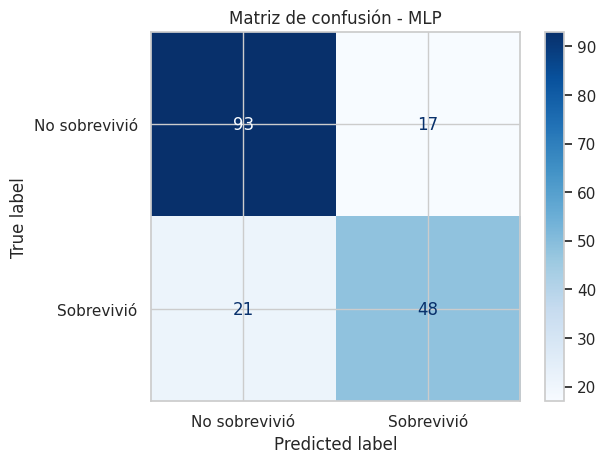

In [29]:
from sklearn.metrics import confusion_matrix

# Generamos las predicciones del modelo MLP
y_pred_mlp = mlp.predict(X_test)

# Mostramos el reporte de clasificación
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred_mlp))

# Calculamos y mostramos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred_mlp)

print("Matriz de confusión:")
print(matriz)

# Visualizamos la matriz
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mlp,
    display_labels=["No sobrevivió", "Sobrevivió"],
    cmap="Blues"
)

plt.title("Matriz de confusión - MLP")
plt.show()

**Tu respuesta (2.4):**

*Al analizar la matriz de confusión, observo que el modelo MLP se equivoca más al predecir a las personas que sobrevivieron. De los 69 pasajeros que realmente sobrevivieron, clasificó incorrectamente a 21 como personas que no sobrevivieron. En cambio, de los 110 pasajeros que no sobrevivieron, clasificó incorrectamente a 17 como sobrevivientes.*

*Esto también se refleja en el recall, es de 0.70 para la clase de sobrevivientes y de 0.85 para la clase de quienes no sobrevivieron. Por lo tanto, el modelo tiene mayor dificultad para identificar correctamente a los sobrevivientes.*

*En un problema real, considero que la gravedad de cada error depende del contexto y de sus consecuencias. Por ejemplo, en un sistema de diagnóstico médico, un falso negativo podría ser más grave porque podría indicar que una persona no tiene una enfermedad cuando en realidad sí la tiene, retrasando su tratamiento. Por otro lado, un falso positivo también puede generar consecuencias, como estudios innecesarios o preocupación.*

*Por eso, es importante analizar qué tipo de error comete el modelo y no evaluar su rendimiento solamente a partir del Accuracy, ya que la importancia de los falsos positivos y falsos negativos cambia según el problema que se quiera resolver.*

**2.5 · Ajuste de hiperparámetros.**
Usá `RandomizedSearchCV` con `StratifiedKFold` (5 particiones) y `scoring="f1_macro"` (o `"accuracy"`, si preferís justificar). Explorá al menos `hidden_layer_sizes`, `alpha` y `activation`. Evaluá el mejor modelo en prueba.

Luego respondé: **¿la mejora respecto del MLP inicial es "real" o está dentro del ruido?** (Pista: compará la diferencia con `std_test_score`).

In [30]:
# Definición de las combinaciones de hiperparámetros que queremos explorar
# Usamos el prefijo 'classifier__' porque en el Pipeline el paso del modelo se llama 'classifier'
distribuciones = {
    "classifier__hidden_layer_sizes": [
        (8,), (16,), (32,), (64,),
        (32, 16), (64, 32)
    ],
    "classifier__alpha": loguniform(1e-5, 1e0),
    "classifier__activation": ["relu", "tanh", "logistic"]
}

# Configuración de la validación cruzada estratificada
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Creación de la búsqueda aleatoria
busqueda = RandomizedSearchCV(
    estimator=mlp,
    param_distributions=distribuciones,
    n_iter=20,
    cv=validacion,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Entrenamiento de la búsqueda usando solamente los datos de entrenamiento
busqueda.fit(X_train, y_train)

# Visualización de los mejores hiperparámetros
print("Mejores hiperparámetros:")
print(busqueda.best_params_)

print("\nMejor F1 macro en validación cruzada:")
print(round(busqueda.best_score_, 3))

# Visualización de la variabilidad del mejor resultado entre particiones
desviacion = busqueda.cv_results_["std_test_score"][busqueda.best_index_]

print("\nDesviación estándar del F1 macro:")
print(round(desviacion, 3))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejores hiperparámetros:
{'classifier__activation': 'relu', 'classifier__alpha': np.float64(1.7070728830306648e-05), 'classifier__hidden_layer_sizes': (32,)}

Mejor F1 macro en validación cruzada:
0.807

Desviación estándar del F1 macro:
0.019


In [31]:
# El mejor modelo encontrado
mejor_mlp = busqueda.best_estimator_

# Predicciones sobre los datos de prueba
y_pred_mejor = mejor_mlp.predict(X_test)

# Evaluación del rendimiento en prueba
accuracy_mejor = accuracy_score(y_test, y_pred_mejor)
f1_mejor = f1_score(y_test, y_pred_mejor, average="macro")

print("Resultados del mejor MLP en prueba:")
print(f"Accuracy: {accuracy_mejor:.3f}")
print(f"F1 macro: {f1_mejor:.3f}")

# Comparación con el MLP inicial
print("\nComparación con el MLP inicial:")
print(f"F1 macro inicial: 0.773")
print(f"F1 macro ajustado: {f1_mejor:.3f}")
print(f"Mejora: {f1_mejor - 0.773:.3f}")

# Comparación de la mejora con la desviación estándar de la validación
print(f"Desviación estándar CV: {desviacion:.3f}")

Resultados del mejor MLP en prueba:
Accuracy: 0.788
F1 macro: 0.766

Comparación con el MLP inicial:
F1 macro inicial: 0.773
F1 macro ajustado: 0.766
Mejora: -0.007
Desviación estándar CV: 0.019


**Tu respuesta (2.5):**

*Para ajustar los hiperparámetros utilicé RandomizedSearchCV con una validación cruzada StratifiedKFold de 5 particiones y la métrica F1-macro como criterio de evaluación. Exploré distintas configuraciones de cantidad de neuronas y capas ocultas (hidden_layer_sizes), regularización (alpha) y función de activación (activation).*

*La mejor configuración encontrada fue una red con una capa oculta de 32 neuronas, función de activación ReLU y un alpha aproximado de 0.00001707. Esta configuración obtuvo un F1-macro promedio de 0.807 durante la validación cruzada, con una desviación estándar de 0.019.*

*Sin embargo, al evaluar el mejor modelo con los datos de prueba, obtuvo un Accuracy de 0.788 y un F1-macro de 0.766. Al compararlo con el MLP inicial, observo que el Accuracy se mantuvo igual, mientras que el F1-macro disminuyó ligeramente de 0.773 a 0.766.*

*Por lo tanto, puedo concluir que el ajuste de hiperparámetros no logró mejorar el rendimiento del modelo sobre los datos de prueba. Aunque durante la validación cruzada se obtuvo un buen resultado, este no se mantuvo completamente al evaluar datos nuevos. Esto demuestra que encontrar la mejor configuración durante la validación no garantiza necesariamente una mejora en el conjunto de prueba.*

**2.6 · Importancia de variables y umbral de decisión.**

**(a)** Calculá la importancia por permutación. ¿Coincide con lo que viste en la exploración?

**(b)** Por defecto, el modelo clasifica como "sobrevivió" si la probabilidad supera **0.5**. Pero podemos elegir otro **umbral**. Con `predict_proba`, calculá la *precisión* y el *recall* de la clase 1 usando umbrales de 0.3, 0.5 y 0.7. ¿Qué ocurre con cada métrica al subir el umbral?

```python
from sklearn.metrics import precision_score, recall_score

probabilidad_sobrevivir = modelo.predict_proba(X_prueba)[:, 1]   # columna de la clase 1
for umbral in [0.3, 0.5, 0.7]:
    pred = (probabilidad_sobrevivir >= umbral).astype(int)
    # calculá precision_score(y_prueba, pred) y recall_score(y_prueba, pred)
```

,variable,importancia,desvio
6,embarked,-0.002,0.011
3,parch,0.020,0.011
1,age,0.027,0.017
2,sibsp,0.029,0.013
4,fare,0.034,0.016
0,pclass,0.042,0.017
5,sex,0.168,0.024


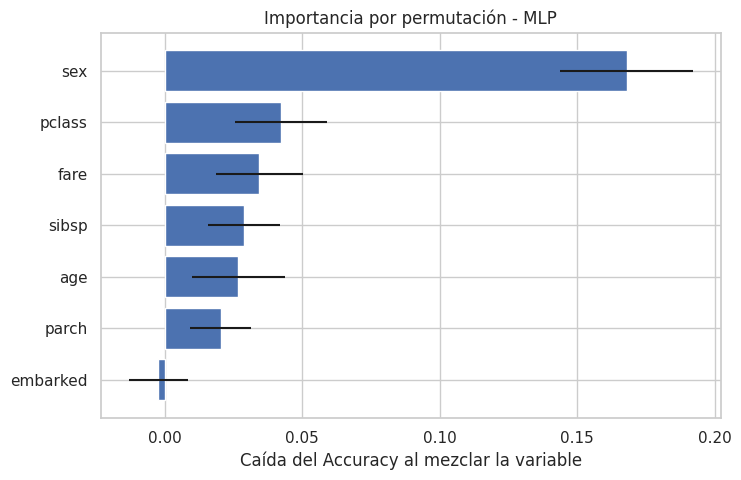

In [32]:
# Calculao de la importancia por permutación
importancias = permutation_importance(
    mejor_mlp,
    X_test,
    y_test,
    n_repeats=30,
    scoring="accuracy",
    random_state=42
)

# Creación de un DataFrame con los resultados
importancias_df = pd.DataFrame({
    "variable": X_test.columns,
    "importancia": importancias.importances_mean,
    "desvio": importancias.importances_std
}).sort_values("importancia", ascending=True)

# Visualización de los resultados
display(importancias_df)

# Grafico de la importancia de cada variable
plt.figure(figsize=(8, 5))

plt.barh(
    importancias_df["variable"],
    importancias_df["importancia"],
    xerr=importancias_df["desvio"]
)

plt.xlabel("Caída del Accuracy al mezclar la variable")
plt.title("Importancia por permutación - MLP")
plt.show()

In [33]:
from sklearn.metrics import precision_score, recall_score

# Obtención de la probabilidad de pertenecer a la clase 1 (sobrevivió)
probabilidad_sobrevivir = mejor_mlp.predict_proba(X_test)[:, 1]

# Prueba de distintos umbrales
resultados_umbrales = []

for umbral in [0.3, 0.5, 0.7]:

    # Converción de las probabilidades en predicciones 0 o 1
    pred = (probabilidad_sobrevivir >= umbral).astype(int)

    # Calculo de la precision y recall
    precision = precision_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)

    resultados_umbrales.append({
        "umbral": umbral,
        "precision": precision,
        "recall": recall
    })

# Visualización de los resultados
resultados_df = pd.DataFrame(resultados_umbrales)

display(resultados_df.round(3))

,umbral,precision,recall
0,0.3,0.690,0.841
1,0.5,0.782,0.623
2,0.7,0.851,0.580


**Tu respuesta (2.6):**

**(a) Importancia de variables por permutación**

Al calcular la importancia por permutación, observo que la variable más importante para el modelo es `sex`, con una importancia de 0.168, seguida por `pclass`, con 0.042. Luego aparecen `fare`, `sibsp`, `age` y `parch`, con valores de importancia menores. Por último, `embarked` presenta una importancia prácticamente nula, incluso ligeramente negativa.

Considero que estos resultados coinciden con lo que observé durante la exploración de los datos. Había encontrado diferencias importantes en la supervivencia según el sexo y la clase del pasajero. Por lo tanto, tiene sentido que estas variables sean las que más influyen en las predicciones del modelo.

**(b) Importancia del umbral de decisión**

Al probar los umbrales de 0.3, 0.5 y 0.7, observo que la Precision aumenta a medida que sube el umbral, pasando de 0.690 a 0.782 y finalmente a 0.851. En cambio, el Recall disminuye de 0.841 a 0.623 y luego a 0.580.

Esto sucede porque, al aumentar el umbral, el modelo se vuelve más exigente para clasificar a una persona como sobreviviente. De esta manera, consigue que sus predicciones positivas sean más precisas, pero también deja de identificar a algunos pasajeros que realmente sobrevivieron.

En conclusión, la elección del umbral depende del objetivo que se quiera priorizar. Si quiero identificar la mayor cantidad posible de sobrevivientes, elegiría un umbral más bajo, como 0.3, para obtener un Recall más alto. En cambio, si quiero que las predicciones de supervivencia sean más precisas, elegiría un umbral más alto, como 0.7. Esto demuestra que no existe un único umbral ideal para todos los problemas, sino que depende de las necesidades y consecuencias de cada situación.

---
## Actividad 3 · Curva de validación: sobreajuste vs. subajuste

Usando el modelo de la Actividad 2 (Titanic) y la técnica del **Paso 7.2** de la Parte 2, construí una **curva de validación** para el hiperparámetro **`alpha`** (regularización) con valores como `[1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]`.

Usá `scoring="accuracy"` y graficá el puntaje de entrenamiento y de validación (con el eje X en escala logarítmica).

Respondé:
1. ¿Con qué valores de `alpha` hay **sobreajuste**? ¿Y **subajuste**?
2. ¿Qué valor elegirías? ¿Coincide con el que encontró la búsqueda aleatoria?

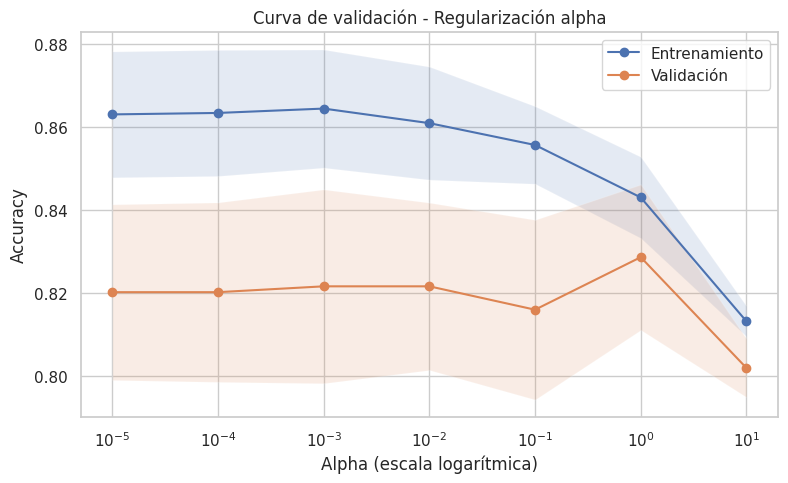

In [34]:
from sklearn.model_selection import validation_curve, StratifiedKFold

# Valores de alpha a probar
valores_alpha = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]

# Configuración de la validación cruzada estratificada
validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculo de la curva de validación
puntajes_entrenamiento, puntajes_validacion = validation_curve(
    estimator=mejor_mlp,
    X=X_train,
    y=y_train,
    param_name="classifier__alpha",
    param_range=valores_alpha,
    cv=validacion,
    scoring="accuracy",
    n_jobs=-1
)

# Calculo de los promedios de cada partición
media_entrenamiento = np.mean(puntajes_entrenamiento, axis=1)
media_validacion = np.mean(puntajes_validacion, axis=1)

# Calculo de la desviación estándar
desvio_entrenamiento = np.std(puntajes_entrenamiento, axis=1)
desvio_validacion = np.std(puntajes_validacion, axis=1)

# Grafico de la curva de validación
plt.figure(figsize=(9, 5))

plt.semilogx(
    valores_alpha,
    media_entrenamiento,
    marker="o",
    label="Entrenamiento"
)

plt.semilogx(
    valores_alpha,
    media_validacion,
    marker="o",
    label="Validación"
)

# Agregado de las bandas de variabilidad
plt.fill_between(
    valores_alpha,
    media_entrenamiento - desvio_entrenamiento,
    media_entrenamiento + desvio_entrenamiento,
    alpha=0.15
)

plt.fill_between(
    valores_alpha,
    media_validacion - desvio_validacion,
    media_validacion + desvio_validacion,
    alpha=0.15
)

plt.xlabel("Alpha (escala logarítmica)")
plt.ylabel("Accuracy")
plt.title("Curva de validación - Regularización alpha")
plt.legend()
plt.grid(True)
plt.show()

In [35]:
tabla_curva = pd.DataFrame({
    "alpha": valores_alpha,
    "accuracy_entrenamiento": media_entrenamiento,
    "accuracy_validacion": media_validacion
})

display(tabla_curva.round(3))

# Identificación del alpha con mejor resultado de validación
mejor_indice = np.argmax(media_validacion)
mejor_alpha_curva = valores_alpha[mejor_indice]

print("Mejor alpha según la curva:", mejor_alpha_curva)
print("Mejor Accuracy de validación:", round(media_validacion[mejor_indice], 3))

,alpha,accuracy_entrenamiento,accuracy_validacion
0,0.000,0.863,0.820
1,0.000,0.863,0.820
2,0.001,0.864,0.822
3,0.010,0.861,0.822
4,0.100,0.856,0.816
5,1.000,0.843,0.829
6,10.000,0.813,0.802


Mejor alpha según la curva: 1
Mejor Accuracy de validación: 0.829


**Tu respuesta (Actividad 3):**

*Al analizar la curva de validación para el hiperparámetro alpha, observo que con valores pequeños, entre 0.00001 y 0.01, existe una diferencia entre el Accuracy de entrenamiento y el de validación. Esto indica cierto sobreajuste, ya que el modelo obtiene mejores resultados con los datos de entrenamiento que con los de validación.*

*Por otro lado, con alpha = 10 observo que el rendimiento disminuye tanto en entrenamiento como en validación, lo que indica un posible subajuste debido a una regularización demasiado fuerte.*

*El mejor resultado de validación se obtiene con alpha = 1, alcanzando un Accuracy de 0.829, mientras que el Accuracy de entrenamiento es de 0.843. Por eso, elegiría este valor, ya que presenta el mejor rendimiento de validación y una diferencia relativamente pequeña entre ambas métricas.*

*Al compararlo con la búsqueda aleatoria de la Actividad 2, observo que no coincide. En aquella búsqueda el mejor alpha fue aproximadamente 0.00001707. Considero que esta diferencia se debe principalmente a que en la búsqueda aleatoria utilicé F1-macro como métrica de evaluación, mientras que en esta actividad utilicé Accuracy. Por lo tanto, cada procedimiento seleccionó el valor que mejor se adaptaba a su propio criterio de evaluación.*

---
## Actividad 4 · Reflexión final

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

4. En el dataset de pingüinos el ajuste de hiperparámetros casi no cambió el resultado. ¿Por qué? ¿Cuándo esperarías que el ajuste sí importe mucho?
5. Si tuvieras que explicarle a alguien sin conocimientos técnicos **por qué no basta con mirar el accuracy**, ¿qué ejemplo le darías?

**Tus respuestas:**

4. Considero que el ajuste casi no modificó los resultados porque el modelo inicial ya lograba reconocer bastante bien los patrones que diferenciaban a las especies de pingüinos. Esperaría que el ajuste de hiperparámetros tuviera un impacto mayor cuando el modelo presenta problemas de sobreajuste o subajuste, cuando los datos son más complejos o cuando la configuración inicial no es adecuada.

5. Le explicaría que el Accuracy puede ser engañoso si hay muchos más casos de una clase que de otra. Por ejemplo, en el Titanic, un modelo que predijera que todos los pasajeros no sobrevivieron tendría un Accuracy de aproximadamente 61,6 %, pero no lograría identificar a ningún sobreviviente. Por eso también es importante analizar otras métricas, como Precision, Recall y F1-macro, para entender mejor cómo se comporta el modelo.


---
# ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

### Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).